# Day 081 | Tabular Deep Learning (TabNet)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| TabNet architecture | DL model designed for tabular data | Pile capacity from soil test parameters |
| Feature attention masks | Network selects which features to use | Identifying most important soil properties |
| Sequential attention | Multi-step feature selection | Progressively refining important features |
| Sparse feature selection | Only a few features used per step | Not all CPT parameters matter equally |
| XGBoost comparison | DL vs gradient boosting baseline | Which approach works better for pile data |
| Interpretability | Built-in feature importance | Which inputs drive pile capacity prediction |

---

## Our Geotechnical Problem

We want to predict **pile capacity** from soil and pile parameters using a TabNet-like architecture,
then compare with XGBoost to see when deep learning helps for tabular data.

```
  Input Features:                Output:
  ─────────────────              ──────────────
  Pile length (m)                Ultimate pile
  Pile diameter (m)              capacity (kN)
  Avg qc (MPa)
  Avg fs (kPa)                 TabNet selects
  Soil type                    which features
  Water table depth (m)        matter most at
  Embedded length (m)          each decision
  SPT N-value                  step
```

## Part 1: Generate Synthetic Pile Capacity Data

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS AND DATA GENERATION
# ───────────────────────────────────────────────────────

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

torch.manual_seed(42)
np.random.seed(42)

def generate_pile_data(n_samples=500):
    """Generate synthetic pile capacity dataset."""
    
    pile_length = np.random.uniform(8, 30, n_samples)        # m
    pile_diameter = np.random.uniform(0.3, 1.2, n_samples)   # m
    avg_qc = np.random.uniform(2, 25, n_samples)             # MPa
    avg_fs = np.random.uniform(10, 120, n_samples)           # kPa
    soil_type = np.random.choice([0, 1, 2], n_samples)       # 0=clay, 1=sand, 2=silt
    water_table = np.random.uniform(0.5, 10, n_samples)      # m
    embedded_length = pile_length * np.random.uniform(0.7, 0.95, n_samples)  # m
    spt_n = np.random.uniform(5, 50, n_samples)              # blow count
    
    # Realistic pile capacity formula (simplified)
    area_base = np.pi * (pile_diameter / 2) ** 2
    perimeter = np.pi * pile_diameter
    
    # End bearing
    Nc_factor = np.where(soil_type == 0, 9.0, np.where(soil_type == 1, 40.0, 20.0))
    q_base = avg_qc * 1000 * 0.15 * Nc_factor / 40  # kPa
    Q_base = q_base * area_base
    
    # Shaft friction
    alpha = np.where(soil_type == 0, 0.5, np.where(soil_type == 1, 0.3, 0.4))
    f_shaft = alpha * avg_fs  # kPa
    Q_shaft = f_shaft * perimeter * embedded_length
    
    # Total capacity with noise
    capacity = Q_base + Q_shaft
    capacity += np.random.normal(0, capacity * 0.08)  # 8% noise
    capacity = np.maximum(capacity, 50)
    
    features = np.column_stack([
        pile_length, pile_diameter, avg_qc, avg_fs,
        soil_type, water_table, embedded_length, spt_n
    ])
    
    feature_names = ['Pile Length', 'Pile Diameter', 'Avg qc', 'Avg fs',
                     'Soil Type', 'Water Table', 'Embedded Length', 'SPT N']
    
    return features, capacity, feature_names

X, y, feature_names = generate_pile_data(n_samples=500)

print(f"Dataset shape: {X.shape}")
print(f"Target range: {y.min():.0f} to {y.max():.0f} kN")
print(f"\nFeature summary:")
for i, name in enumerate(feature_names):
    print(f"  {name:>18}: {X[:, i].min():8.2f} to {X[:, i].max():8.2f}")

Dataset shape: (500, 8)
Target range: 101 to 5277 kN

Feature summary:
         Pile Length:     8.11 to    29.85
       Pile Diameter:     0.30 to     1.20
              Avg qc:     2.11 to    24.99
              Avg fs:    10.35 to   119.82
           Soil Type:     0.00 to     2.00
         Water Table:     0.50 to     9.98
     Embedded Length:     5.80 to    27.43
               SPT N:     5.03 to    49.98


In [2]:
# ───────────────────────────────────────────────────────
# TRAIN/TEST SPLIT AND NORMALIZATION
# ───────────────────────────────────────────────────────

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# Convert to tensors
X_tr = torch.tensor(X_train_scaled, dtype=torch.float32)
y_tr = torch.tensor(y_train_scaled, dtype=torch.float32).unsqueeze(1)
X_te = torch.tensor(X_test_scaled, dtype=torch.float32)
y_te = torch.tensor(y_test_scaled, dtype=torch.float32).unsqueeze(1)

print(f"Train: {X_tr.shape}, Test: {X_te.shape}")

Train: torch.Size([400, 8]), Test: torch.Size([100, 8])


---

## Part 2: Simplified TabNet Architecture

TabNet uses **sequential attention steps** where each step selects a subset of features.
We implement a simplified version with the core ideas:

1. **Attention transformer**: learns which features to use at each step
2. **Feature transformer**: processes selected features
3. **Multiple decision steps**: progressively refine predictions

In [3]:
# ───────────────────────────────────────────────────────
# SIMPLIFIED TABNET ARCHITECTURE
# ───────────────────────────────────────────────────────

class AttentionTransformer(nn.Module):
    """Learns which features to attend to at each step."""
    
    def __init__(self, in_features, out_features):
        super().__init__()
        self.fc = nn.Linear(in_features, out_features, bias=False)
        self.bn = nn.BatchNorm1d(out_features)
    
    def forward(self, x, prior_scales):
        # prior_scales: accumulated attention (to encourage diversity)
        x = self.fc(x)
        x = self.bn(x)
        x = x * prior_scales  # modulate by prior attention
        x = torch.softmax(x, dim=-1)  # sparse attention mask
        return x


class FeatureTransformer(nn.Module):
    """Processes selected features to produce step output."""
    
    def __init__(self, in_features, hidden_dim, out_features):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_features)
        self.bn2 = nn.BatchNorm1d(out_features)
    
    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.bn2(self.fc2(x))
        return x


class SimpleTabNet(nn.Module):
    """Simplified TabNet for tabular regression."""
    
    def __init__(self, in_features, hidden_dim=64, n_steps=3,
                 step_dim=32, gamma=1.3):
        super().__init__()
        self.n_steps = n_steps
        self.gamma = gamma
        
        # Initial batch normalization
        self.initial_bn = nn.BatchNorm1d(in_features)
        
        # Shared feature transformer (shared across steps)
        self.shared_fc = nn.Linear(in_features, hidden_dim)
        self.shared_bn = nn.BatchNorm1d(hidden_dim)
        
        # Step-specific components
        self.attention_transforms = nn.ModuleList([
            AttentionTransformer(hidden_dim, in_features)
            for _ in range(n_steps)
        ])
        self.feature_transforms = nn.ModuleList([
            FeatureTransformer(in_features, hidden_dim, step_dim)
            for _ in range(n_steps)
        ])
        
        # Final prediction layer
        self.final_fc = nn.Linear(step_dim, 1)
    
    def forward(self, x, return_masks=False):
        x = self.initial_bn(x)
        
        # Prior scales: initialized to ones (all features equally available)
        prior_scales = torch.ones(x.shape[0], x.shape[1], device=x.device)
        
        # Shared feature processing
        h = F.relu(self.shared_bn(self.shared_fc(x)))
        
        aggregated = torch.zeros(x.shape[0], self.feature_transforms[0].fc2.out_features,
                                 device=x.device)
        masks = []
        
        for step in range(self.n_steps):
            # Attention: which features to focus on
            mask = self.attention_transforms[step](h, prior_scales)
            masks.append(mask)
            
            # Update prior scales (encourage diversity)
            prior_scales = prior_scales * (self.gamma - mask)
            
            # Apply mask and transform
            masked_x = mask * x
            step_output = self.feature_transforms[step](masked_x)
            aggregated = aggregated + F.relu(step_output)
        
        # Final prediction
        output = self.final_fc(aggregated)
        
        if return_masks:
            return output, masks
        return output

tabnet = SimpleTabNet(in_features=8, hidden_dim=64, n_steps=3, step_dim=32)
print(tabnet)
print(f"\nTotal parameters: {sum(p.numel() for p in tabnet.parameters()):,}")

SimpleTabNet(
  (initial_bn): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (shared_fc): Linear(in_features=8, out_features=64, bias=True)
  (shared_bn): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (attention_transforms): ModuleList(
    (0-2): 3 x AttentionTransformer(
      (fc): Linear(in_features=64, out_features=8, bias=False)
      (bn): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (feature_transforms): ModuleList(
    (0-2): 3 x FeatureTransformer(
      (fc1): Linear(in_features=8, out_features=64, bias=True)
      (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (fc2): Linear(in_features=64, out_features=32, bias=True)
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (final_fc): Linear(in_features=32, out_features=1, bias=True)
)

Total parameters: 10,881


---

## Part 3: Train TabNet

In [4]:
# ───────────────────────────────────────────────────────
# TRAIN TABNET
# ───────────────────────────────────────────────────────

tabnet = SimpleTabNet(in_features=8, hidden_dim=64, n_steps=3, step_dim=32)
optimizer = torch.optim.Adam(tabnet.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.MSELoss()

n_epochs = 300
batch_size = 64
losses = []

for epoch in range(n_epochs):
    tabnet.train()
    epoch_loss = 0
    n_batches = 0
    
    # Mini-batch training
    perm = torch.randperm(X_tr.shape[0])
    for i in range(0, X_tr.shape[0], batch_size):
        idx = perm[i:i + batch_size]
        X_batch = X_tr[idx]
        y_batch = y_tr[idx]
        
        optimizer.zero_grad()
        y_pred = tabnet(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        n_batches += 1
    
    avg_loss = epoch_loss / n_batches
    losses.append(avg_loss)
    
    if epoch % 50 == 0 or epoch == n_epochs - 1:
        tabnet.eval()
        with torch.no_grad():
            y_pred_test = tabnet(X_te)
            test_loss = criterion(y_pred_test, y_te).item()
        print(f"Epoch {epoch:3d}/{n_epochs} | Train Loss: {avg_loss:.4f} | Test Loss: {test_loss:.4f}")

print("\nTabNet training complete!")

Epoch   0/300 | Train Loss: 0.6069 | Test Loss: 0.6385


Epoch  50/300 | Train Loss: 0.0479 | Test Loss: 0.0846


Epoch 100/300 | Train Loss: 0.0456 | Test Loss: 0.0776


Epoch 150/300 | Train Loss: 0.0425 | Test Loss: 0.0597


Epoch 200/300 | Train Loss: 0.0568 | Test Loss: 0.0578


Epoch 250/300 | Train Loss: 0.0375 | Test Loss: 0.0649


Epoch 299/300 | Train Loss: 0.0391 | Test Loss: 0.0604

TabNet training complete!


---

## Part 4: XGBoost Comparison

In [5]:
# ───────────────────────────────────────────────────────
# XGBOOST BASELINE
# ───────────────────────────────────────────────────────

try:
    from sklearn.ensemble import GradientBoostingRegressor
    
    xgb_model = GradientBoostingRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42
    )
    xgb_model.fit(X_train_scaled, y_train)
    
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    r2_xgb = r2_score(y_test, y_pred_xgb)
    rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
    
    print(f"XGBoost Results:")
    print(f"  R2:   {r2_xgb:.4f}")
    print(f"  RMSE: {rmse_xgb:.2f} kN")
    
    has_xgb = True
except ImportError:
    print("sklearn GradientBoosting used as XGBoost alternative")
    has_xgb = False

# TabNet predictions
tabnet.eval()
with torch.no_grad():
    y_pred_tabnet_scaled = tabnet(X_te).numpy().flatten()
    y_pred_tabnet = scaler_y.inverse_transform(y_pred_tabnet_scaled.reshape(-1, 1)).flatten()

r2_tabnet = r2_score(y_test, y_pred_tabnet)
rmse_tabnet = np.sqrt(mean_squared_error(y_test, y_pred_tabnet))

print(f"\nTabNet Results:")
print(f"  R2:   {r2_tabnet:.4f}")
print(f"  RMSE: {rmse_tabnet:.2f} kN")

if has_xgb:
    print(f"\nComparison:")
    print(f"  {'Model':<12} {'R2':>8} {'RMSE (kN)':>10}")
    print(f"  {'─' * 32}")
    print(f"  {'TabNet':<12} {r2_tabnet:>8.4f} {rmse_tabnet:>10.2f}")
    print(f"  {'XGBoost':<12} {r2_xgb:>8.4f} {rmse_xgb:>10.2f}")

XGBoost Results:
  R2:   0.8781
  RMSE: 296.24 kN

TabNet Results:
  R2:   0.9069
  RMSE: 258.84 kN

Comparison:
  Model              R2  RMSE (kN)
  ────────────────────────────────
  TabNet         0.9069     258.84
  XGBoost        0.8781     296.24


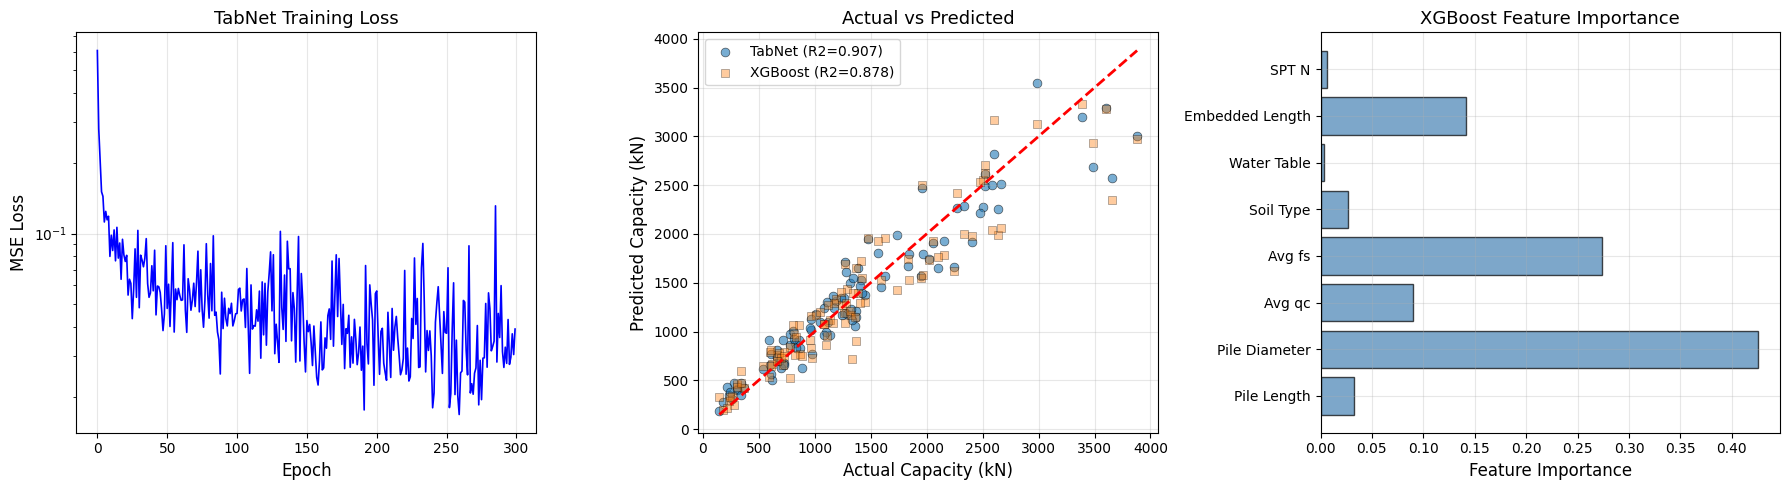

In [6]:
# ───────────────────────────────────────────────────────
# COMPARISON PLOTS
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training loss
axes[0].semilogy(losses, 'b-', linewidth=1.2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('MSE Loss', fontsize=12)
axes[0].set_title('TabNet Training Loss', fontsize=13)
axes[0].grid(True, alpha=0.3)

# TabNet predictions
axes[1].scatter(y_test, y_pred_tabnet, alpha=0.6, edgecolors='k',
                linewidth=0.5, s=40, label=f'TabNet (R2={r2_tabnet:.3f})')
if has_xgb:
    axes[1].scatter(y_test, y_pred_xgb, alpha=0.4, edgecolors='k',
                    linewidth=0.5, s=40, marker='s', label=f'XGBoost (R2={r2_xgb:.3f})')
lims = [min(y_test.min(), y_pred_tabnet.min()), max(y_test.max(), y_pred_tabnet.max())]
axes[1].plot(lims, lims, 'r--', linewidth=2)
axes[1].set_xlabel('Actual Capacity (kN)', fontsize=12)
axes[1].set_ylabel('Predicted Capacity (kN)', fontsize=12)
axes[1].set_title('Actual vs Predicted', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

# Feature importance comparison
if has_xgb:
    xgb_importance = xgb_model.feature_importances_
    x_pos = np.arange(len(feature_names))
    axes[2].barh(x_pos, xgb_importance, color='steelblue', edgecolor='k', alpha=0.7)
    axes[2].set_yticks(x_pos)
    axes[2].set_yticklabels(feature_names)
    axes[2].set_xlabel('Feature Importance', fontsize=12)
    axes[2].set_title('XGBoost Feature Importance', fontsize=13)
    axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Part 5: TabNet Feature Attention Masks

TabNet's key advantage: we can extract **attention masks** to see which features the network
selects at each decision step.

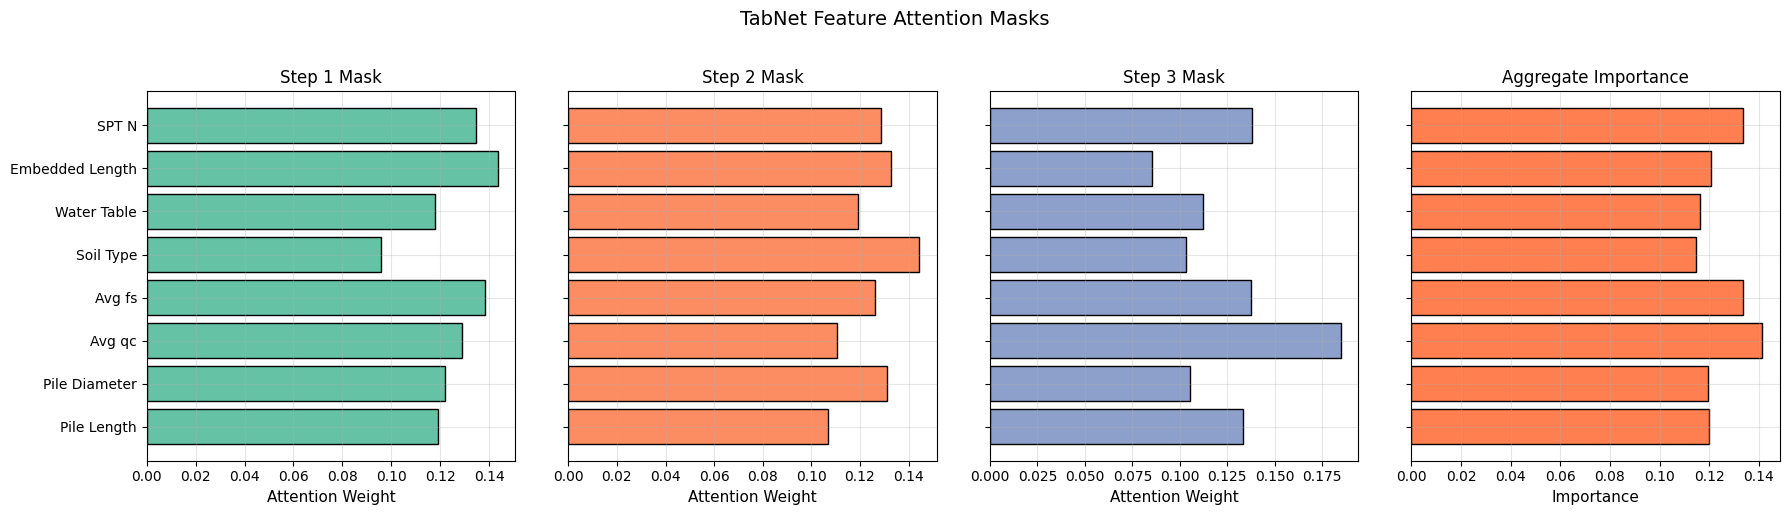

Feature importance from TabNet attention:
              Avg qc: 0.1415
               SPT N: 0.1338
              Avg fs: 0.1338
     Embedded Length: 0.1206
         Pile Length: 0.1199
       Pile Diameter: 0.1195
         Water Table: 0.1164
           Soil Type: 0.1146


In [7]:
# ───────────────────────────────────────────────────────
# EXTRACT AND VISUALIZE ATTENTION MASKS
# ───────────────────────────────────────────────────────

tabnet.eval()
with torch.no_grad():
    _, masks = tabnet(X_te, return_masks=True)

# Average masks across test samples
avg_masks = [m.numpy().mean(axis=0) for m in masks]

fig, axes = plt.subplots(1, len(avg_masks) + 1, figsize=(18, 5))

# Individual step masks
for step, (mask, ax) in enumerate(zip(avg_masks, axes[:-1])):
    ax.barh(range(len(feature_names)), mask, color=plt.cm.Set2(step), edgecolor='k')
    ax.set_yticks(range(len(feature_names)))
    ax.set_yticklabels(feature_names if step == 0 else [])
    ax.set_xlabel('Attention Weight', fontsize=11)
    ax.set_title(f'Step {step + 1} Mask', fontsize=12)
    ax.grid(True, alpha=0.3)

# Aggregate mask (all steps combined)
aggregate_mask = np.mean(avg_masks, axis=0)
aggregate_mask = aggregate_mask / aggregate_mask.sum()  # normalize
axes[-1].barh(range(len(feature_names)), aggregate_mask, color='coral', edgecolor='k')
axes[-1].set_yticks(range(len(feature_names)))
axes[-1].set_yticklabels([])
axes[-1].set_xlabel('Importance', fontsize=11)
axes[-1].set_title('Aggregate Importance', fontsize=12)
axes[-1].grid(True, alpha=0.3)

plt.suptitle('TabNet Feature Attention Masks', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Feature importance from TabNet attention:")
for name, imp in sorted(zip(feature_names, aggregate_mask), key=lambda x: -x[1]):
    print(f"  {name:>18}: {imp:.4f}")

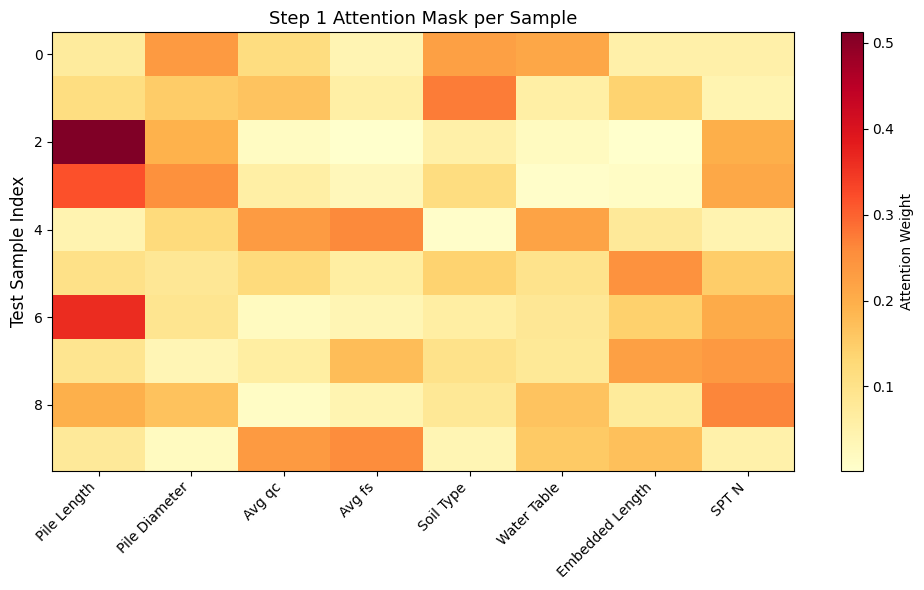

Different samples may attend to different features.
This is instance-wise feature selection — a key TabNet advantage.


In [8]:
# ───────────────────────────────────────────────────────
# SAMPLE-LEVEL ATTENTION MASKS
# ───────────────────────────────────────────────────────

# Show attention masks for individual test samples
n_show = 10
mask_matrix = masks[0][:n_show].numpy()  # Step 1 masks for first 10 samples

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
im = ax.imshow(mask_matrix, cmap='YlOrRd', aspect='auto')
plt.colorbar(im, ax=ax, label='Attention Weight')
ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=45, ha='right')
ax.set_ylabel('Test Sample Index', fontsize=12)
ax.set_title('Step 1 Attention Mask per Sample', fontsize=13)
plt.tight_layout()
plt.show()

print("Different samples may attend to different features.")
print("This is instance-wise feature selection — a key TabNet advantage.")

---

## Part 6: When to Use TabNet vs XGBoost

| Criterion | TabNet | XGBoost |
|-----------|--------|--------|
| Small data (< 1000) | Weaker | Stronger |
| Large data (> 10000) | Competitive | Strong |
| Interpretability | Attention masks | Feature importance |
| Training time | Longer | Faster |
| Feature selection | Built-in (instance-wise) | Post-hoc (global) |
| End-to-end learning | Yes | Separate preprocessing |

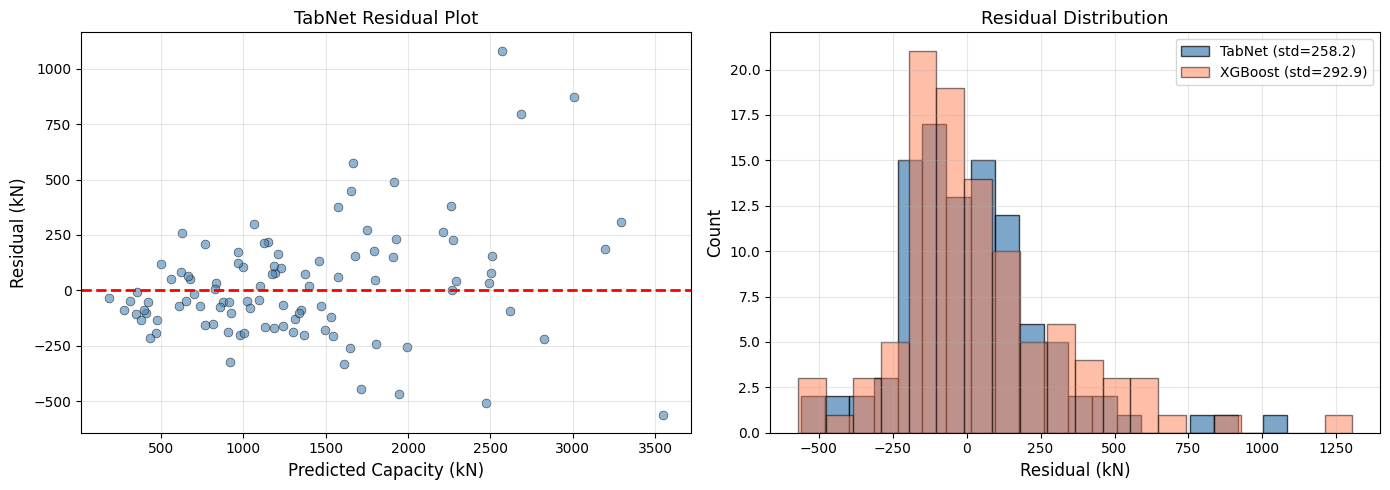

In [9]:
# ───────────────────────────────────────────────────────
# RESIDUAL ANALYSIS
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TabNet residuals
residuals_tabnet = y_test - y_pred_tabnet
axes[0].scatter(y_pred_tabnet, residuals_tabnet, alpha=0.6, edgecolors='k',
                linewidth=0.5, s=40, color='steelblue')
axes[0].axhline(y=0, color='r', linewidth=2, linestyle='--')
axes[0].set_xlabel('Predicted Capacity (kN)', fontsize=12)
axes[0].set_ylabel('Residual (kN)', fontsize=12)
axes[0].set_title('TabNet Residual Plot', fontsize=13)
axes[0].grid(True, alpha=0.3)

# Residual distribution
axes[1].hist(residuals_tabnet, bins=20, color='steelblue', edgecolor='k', alpha=0.7,
             label=f'TabNet (std={residuals_tabnet.std():.1f})')
if has_xgb:
    residuals_xgb = y_test - y_pred_xgb
    axes[1].hist(residuals_xgb, bins=20, color='coral', edgecolor='k', alpha=0.5,
                 label=f'XGBoost (std={residuals_xgb.std():.1f})')
axes[1].set_xlabel('Residual (kN)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('Residual Distribution', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Practice Exercises

### Exercise 1: Vary Decision Steps
Try `n_steps=1` vs `n_steps=5`. How does the number of attention steps affect accuracy?

### Exercise 2: Add More Features
Add new features (e.g., overburden pressure, soil plasticity). Does TabNet correctly identify them as important?

### Exercise 3: Classification Task
Convert to a classification problem: predict pile capacity class (Low/Medium/High). Modify the output layer.

In [10]:
# EXERCISE SPACE

# Exercise 1: Different number of steps
# tabnet_1 = SimpleTabNet(in_features=8, n_steps=1)
# tabnet_5 = SimpleTabNet(in_features=8, n_steps=5)

# Exercise 2: Add features
# Add columns to feature matrix and regenerate data

# Exercise 3: Classification
# Change final_fc output to n_classes
# Use CrossEntropyLoss instead of MSELoss

---

## Key Takeaways

1. **TabNet brings attention to tabular data.** Unlike standard MLPs, TabNet learns which features to select at each decision step.

2. **Feature attention masks provide interpretability.** We can see exactly which soil properties the model uses for each prediction.

3. **Instance-wise feature selection is powerful.** Different pile configurations may depend on different soil parameters.

4. **XGBoost remains competitive for small datasets.** With fewer than ~1000 samples, gradient boosting often wins due to lower data requirements.

5. **TabNet excels with larger datasets and end-to-end learning.** When you have abundant data and want built-in feature selection, TabNet is a strong choice.

---

## How This Connects to ML

| TabNet Concept | Traditional ML Equivalent |
|---|---|
| Attention mask | Feature selection (but learned, not manual) |
| Sequential steps | Ensemble of weak learners (like boosting) |
| Sparse selection | L1 regularization / LASSO |
| Instance-wise importance | SHAP values (but built into the model) |
| End-to-end training | Separate feature engineering + model |

**TabNet bridges the gap between tree-based models and deep learning for tabular data** — tomorrow we explore hyperparameter tuning for DL.

---

*Day 081 of 100 — Even tables deserve attention!*